# 01 Data and randomization checks

Data: Kevin Hillstrom's MineThatData E-Mail Analytics Challenge (2008), a public dataset from a US retailer. 64,000 past customers were randomly split into three arms: Mens E-Mail, Womens E-Mail and No E-Mail.

This notebook only looks at the data and checks that the randomization worked. No outcome is compared across arms here. That happens only after `analysis_plan.md` is committed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from helpers import load_data

df = load_data()
print("Rows:", len(df))
print("Columns:", len(df.columns))
df.head()

Rows: 64000
Columns: 21


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,...,spend,zip_urban,zip_suburban,channel_web,channel_multi,mens_email,womens_email,any_email,recent,past_category
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,...,0.0,0,1,0,0,0,1,1,0,mens only
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,...,0.0,0,0,1,0,0,0,0,1,both
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,...,0.0,0,1,1,0,0,1,1,0,womens only
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,...,0.0,0,0,1,0,1,0,1,0,mens only
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,...,0.0,1,0,1,0,0,1,1,1,mens only


## 1. Inspect the data

In [2]:
raw_columns = ["recency", "history_segment", "history", "mens", "womens", "zip_code", "newbie", "channel", "segment", "visit", "conversion", "spend"]
print(df[raw_columns].dtypes)
print()
print("Missing values in total:", df[raw_columns].isna().sum().sum())
print("Fully duplicated rows:", df[raw_columns].duplicated().sum())

recency              int64
history_segment        str
history            float64
mens                 int64
womens               int64
zip_code               str
newbie               int64
channel                str
segment                str
visit                int64
conversion           int64
spend              float64
dtype: object

Missing values in total: 0
Fully duplicated rows: 6562


In [3]:
df[["recency", "history", "mens", "womens", "newbie"]].describe().round(2)

,recency,history,mens,womens,newbie
count,64000.00,64000.00,64000.00,64000.00,64000.0
mean,5.76,242.09,0.55,0.55,0.5
std,3.51,256.16,0.50,0.50,0.5
min,1.00,29.99,0.00,0.00,0.0
25%,2.00,64.66,0.00,0.00,0.0
50%,6.00,158.11,1.00,1.00,1.0
75%,9.00,325.66,1.00,1.00,1.0
max,12.00,3345.93,1.00,1.00,1.0


In [4]:
for col in ["history_segment", "zip_code", "channel", "segment"]:
    print(df[col].value_counts().sort_index())
    print()

history_segment
1) $0 - $100        22970
2) $100 - $200      14254
3) $200 - $350      12289
4) $350 - $500       6409
5) $500 - $750       4911
6) $750 - $1,000     1859
7) $1,000 +          1308
Name: count, dtype: int64

zip_code
Rural         9563
Surburban    28776
Urban        25661
Name: count, dtype: int64

channel
Multichannel     7762
Phone           28021
Web             28217
Name: count, dtype: int64

segment
Mens E-Mail      21307
No E-Mail        21306
Womens E-Mail    21387
Name: count, dtype: int64



In [5]:
both_zero = ((df["mens"] == 0) & (df["womens"] == 0)).sum()
print("Customers with mens = 0 and womens = 0:", both_zero)
print(df["past_category"].value_counts())

Customers with mens = 0 and womens = 0: 0
past_category
mens only      28818
womens only    28734
both            6448
Name: count, dtype: int64


Outcome columns are checked only as pooled numbers over all 64,000 customers, never split by arm.

In [6]:
print("Pooled visit rate:", round(df["visit"].mean(), 4))
print("Pooled conversion rate:", round(df["conversion"].mean(), 4))
print("Pooled mean spend:", round(df["spend"].mean(), 4))
print("Share of customers with spend > 0:", round((df["spend"] > 0).mean(), 4))
print("Max spend:", df["spend"].max())
print("Spend > 0 but conversion = 0:", ((df["spend"] > 0) & (df["conversion"] == 0)).sum())
print("Conversion = 1 but visit = 0:", ((df["conversion"] == 1) & (df["visit"] == 0)).sum())

Pooled visit rate: 0.1468
Pooled conversion rate: 0.009
Pooled mean spend: 1.0509
Share of customers with spend > 0: 0.009
Max spend: 499.0
Spend > 0 but conversion = 0: 0
Conversion = 1 but visit = 0: 0


In [7]:
buyers = df[df["spend"] > 0]
print("Spend among buyers:")
print(buyers["spend"].describe().round(2))
print("99th percentile of spend (all customers):", df["spend"].quantile(0.99))

Spend among buyers:
count    578.00
mean     116.36
std      107.87
min       29.99
25%       32.27
50%       80.80
75%      153.35
max      499.00
Name: spend, dtype: float64
99th percentile of spend (all customers): 0.0


## 2. Sample ratio mismatch (SRM) check

If the assignment really was 1/3 each, the arm sizes should be close to 64,000 / 3. A chi-square goodness-of-fit test checks this.

In [8]:
observed = df["segment"].value_counts().sort_index()
expected = np.array([len(df) / 3, len(df) / 3, len(df) / 3])
chi2, p_srm = stats.chisquare(observed.values, expected)

print(observed)
print("Expected in each arm:", round(len(df) / 3, 1))
print("Chi-square:", round(chi2, 3))
print("p-value:", round(p_srm, 4))

segment
Mens E-Mail      21307
No E-Mail        21306
Womens E-Mail    21387
Name: count, dtype: int64
Expected in each arm: 21333.3
Chi-square: 0.203
p-value: 0.9037


## 3. Balance table

For each pre-treatment variable: mean by arm, and the standardized mean difference (SMD) of each email arm vs control.

SMD = (mean_treat - mean_control) / sqrt((var_treat + var_control) / 2). The usual rule of thumb flags |SMD| > 0.1.

In [9]:
df["zip_rural"] = (df["zip_code"] == "Rural").astype(int)
df["channel_phone"] = (df["channel"] == "Phone").astype(int)

balance_vars = ["recency", "history", "mens", "womens", "newbie", "zip_urban", "zip_suburban", "zip_rural", "channel_phone", "channel_web", "channel_multi"]

control = df[df["segment"] == "No E-Mail"]
mens = df[df["segment"] == "Mens E-Mail"]
womens = df[df["segment"] == "Womens E-Mail"]

rows = []
for var in balance_vars:
    c_mean = control[var].mean()
    m_mean = mens[var].mean()
    w_mean = womens[var].mean()
    smd_mens = (m_mean - c_mean) / np.sqrt((mens[var].var() + control[var].var()) / 2)
    smd_womens = (w_mean - c_mean) / np.sqrt((womens[var].var() + control[var].var()) / 2)
    rows.append([var, c_mean, m_mean, w_mean, smd_mens, smd_womens])

balance = pd.DataFrame(rows, columns=["variable", "no_email", "mens_email", "womens_email", "smd_mens_vs_control", "smd_womens_vs_control"])
balance = balance.round(4)
balance.to_csv("results/balance_table.csv", index=False)
balance

,variable,no_email,mens_email,womens_email,smd_mens_vs_control,smd_womens_vs_control
0,recency,5.7497,5.7736,5.7678,0.0068,0.0052
1,history,240.8827,242.8359,242.5366,0.0076,0.0065
2,mens,0.5532,0.5509,0.5489,-0.0046,-0.0086
3,womens,0.5476,0.5514,0.5501,0.0076,0.0049
4,newbie,0.5020,0.5015,0.5032,-0.0009,0.0026
5,zip_urban,0.4009,0.4019,0.4001,0.0020,-0.0018
6,zip_suburban,0.4518,0.4459,0.4512,-0.0117,-0.0011
7,zip_rural,0.1473,0.1522,0.1487,0.0137,0.0040
8,channel_phone,0.4378,0.4337,0.4420,-0.0083,0.0086
9,channel_web,0.4399,0.4454,0.4374,0.0110,-0.0051


In [10]:
max_smd = balance[["smd_mens_vs_control", "smd_womens_vs_control"]].abs().max().max()
print("Largest |SMD|:", round(max_smd, 4))
print("Any |SMD| > 0.1:", max_smd > 0.1)

Largest |SMD|: 0.0137
Any |SMD| > 0.1: False


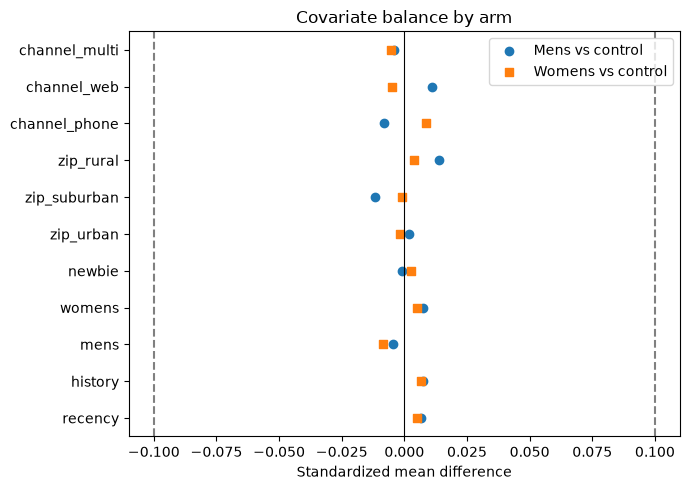

In [11]:
plt.figure(figsize=(7, 5))
positions = np.arange(len(balance_vars))
plt.scatter(balance["smd_mens_vs_control"], positions, label="Mens vs control")
plt.scatter(balance["smd_womens_vs_control"], positions, marker="s", label="Womens vs control")
plt.axvline(0.1, color="grey", linestyle="--")
plt.axvline(-0.1, color="grey", linestyle="--")
plt.axvline(0, color="black", linewidth=0.8)
plt.yticks(positions, balance_vars)
plt.xlabel("Standardized mean difference")
plt.title("Covariate balance by arm")
plt.legend()
plt.tight_layout()
plt.savefig("figures/balance_smd.png", dpi=150)
plt.show()

## 4. Joint balance test

Regress the treatment dummy on all covariates (using only that arm plus control). If randomization worked, the covariates should not predict treatment, so the F-test of all slopes = 0 should not reject. HC2 robust covariance is used.

In [12]:
covariates = ["recency", "history", "mens", "womens", "newbie", "zip_urban", "zip_suburban", "channel_web", "channel_multi"]

mens_sample = df[df["segment"] != "Womens E-Mail"]
X = sm.add_constant(mens_sample[covariates])
model_mens = sm.OLS(mens_sample["mens_email"], X).fit(cov_type="HC2")
r_matrix = np.eye(len(covariates) + 1)[1:]
f_mens = model_mens.f_test(r_matrix)
print("Mens email vs control: F =", round(float(f_mens.fvalue), 3), " p =", round(float(f_mens.pvalue), 4))

womens_sample = df[df["segment"] != "Mens E-Mail"]
X = sm.add_constant(womens_sample[covariates])
model_womens = sm.OLS(womens_sample["womens_email"], X).fit(cov_type="HC2")
f_womens = model_womens.f_test(r_matrix)
print("Womens email vs control: F =", round(float(f_womens.fvalue), 3), " p =", round(float(f_womens.pvalue), 4))

Mens email vs control: F = 0.705  p = 0.7047


Womens email vs control: F = 0.43  p = 0.92


## 5. Power and minimum detectable effect (MDE)

For a difference in two proportions with base rate p, arm sizes n_t and n_c, significance level alpha (two-sided) and power 1 - beta:

MDE = (z_{1-alpha/2} + z_{1-beta}) * sqrt(p(1-p)(1/n_t + 1/n_c))

p is the pooled rate over all 64,000 customers, so no treatment effect is seen here. Power is 80%. Because of the Holm correction with 2 primary tests, the first test is run at alpha = 0.025, so both 0.05 and 0.025 are shown.

In [13]:
n_control = len(control)
n_mens = len(mens)
n_womens = len(womens)
z_power = stats.norm.ppf(0.80)

rows = []
for outcome in ["visit", "conversion"]:
    p = df[outcome].mean()
    for alpha in [0.05, 0.025]:
        z_alpha = stats.norm.ppf(1 - alpha / 2)
        se_mens = np.sqrt(p * (1 - p) * (1 / n_mens + 1 / n_control))
        mde = (z_alpha + z_power) * se_mens
        rows.append([outcome, round(p, 4), alpha, round(mde, 4), round(mde / p * 100, 1)])

sd_spend = df["spend"].std()
for alpha in [0.05, 0.025]:
    z_alpha = stats.norm.ppf(1 - alpha / 2)
    se_spend = sd_spend * np.sqrt(1 / n_mens + 1 / n_control)
    mde = (z_alpha + z_power) * se_spend
    rows.append(["spend", round(df["spend"].mean(), 4), alpha, round(mde, 4), round(mde / df["spend"].mean() * 100, 1)])

mde_table = pd.DataFrame(rows, columns=["outcome", "pooled_base", "alpha", "mde_absolute", "mde_relative_pct"])
mde_table.to_csv("results/mde_table.csv", index=False)
mde_table

,outcome,pooled_base,alpha,mde_absolute,mde_relative_pct
0,visit,0.1468,0.050,0.0096,6.5
1,visit,0.1468,0.025,0.0106,7.2
2,conversion,0.0090,0.050,0.0026,28.4
3,conversion,0.0090,0.025,0.0028,31.3
4,spend,1.0509,0.050,0.4081,38.8
5,spend,1.0509,0.025,0.4491,42.7


## Summary

- 64,000 rows, 12 columns, no missing values. 6,562 rows are exact duplicates, which is expected because there is no customer ID and the covariates are coarse.
- Arm sizes are 21,306 / 21,307 / 21,387. The SRM chi-square is 0.20 (p = 0.90), so the split matches 1/3 each.
- The largest |SMD| is 0.014, far below 0.1. The joint F-tests give p = 0.70 (mens) and p = 0.92 (womens). The randomization looks fine.
- Only 0.9% of customers bought anything, so the 99th percentile of spend over all customers is 0. Winsorizing there would wipe out spend completely, so the plan winsorizes at the 99th percentile of positive spend instead.
- With about 21,300 customers per arm and 80% power, the MDE is about 1 percentage point for visit (7% of the base rate), 0.26 to 0.28 points for conversion (about 30%) and about $0.41 to $0.45 for spend (about 40%). Visit is well powered, conversion and spend only for large effects.

Next step: write and commit `analysis_plan.md` before any outcome is compared across arms.